<a id="phase-1"></a>

# 1. Business Understanding

Semester project, summer 2026, HdM Stuttgart: classify whether a customer uses the latest watch model.
The notebook covers data checks, preparation, model comparison and evaluation.
Label 1 means latest model; label 0 means older model. Selection uses **macro-F1**, supported by **accuracy**.
Details: [Process overview](CRISP-DM-Process-Overview.md).


In [1]:
from pathlib import Path
import hashlib
import io
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "User of latest model"
ID = "ID"
DATE = "Most current software update"
SPORT_HOURS = ["Swimming Hours per Week", "Biking Hours per Week", "Running Hours per Week"]
TOTAL_HOURS = "Total Training Hours per Week"
ROOT = Path.cwd()
TRAIN_FILE = ROOT / "data/triathlon_watch_training_data_final.csv"
TEST_FILE = ROOT / "data/triathlon_watch_test_data_final.csv"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})


<a id="phase-2"></a>

# 2. Data Understanding

We read the unchanged original files and initially explore only the training file.
The test file remains outside model selection.


In [2]:
raw = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)
assert list(raw.columns) == list(test.columns)
assert len(raw.columns) == 21
input_hashes = {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
                for path in [TRAIN_FILE, TEST_FILE]}
print(f"Training: {raw.shape} | Provided test: {test.shape}")
display(raw.head(3))


Training: (1000, 21) | Provided test: (500, 21)


,ID,Age of customer,Sex,Ctry,Town,Swimming Hours per Week,Biking Hours per Week,Running Hours per Week,Total Training Hours per Week,VO2 Max,...,Calories Burned per Week,Support Cases of Customer,Customer Years,Most current software update,Goal of Training,Preferred Training Daytime,Subscription Type,Color of Watch,Synchronisation,User of latest model
0,C0001,61.0,Other,UK,Birmingham,2.52,0.10,1.78,4.40,23.08,...,2329.95,2.0,1.0,2024-07-22,Fitness,Evening,Free,White,Yes,1.0
1,C0003,57.0,Other,Australia,Sydney,1.55,10.01,4.57,16.13,39.04,...,7904.93,2.0,1.0,2024-05-11,Fitness,Evening,Premium,Black,Yes,0.0
2,C0004,30.0,Other,India,Bangalore,1.19,12.04,8.64,21.87,71.59,...,10839.81,2.0,0.0,2024-08-16,Competition,Afternoon,Free,White,Yes,1.0


In [3]:
overview = pd.DataFrame({
    "Data type": raw.dtypes.astype(str),
    "Missing values": raw.isna().sum(),
    "Unique values": raw.nunique(),
})
display(overview)
display(pd.Series({
    "Completely empty rows": raw.isna().all(axis=1).sum(),
    "Missing labels": raw[TARGET].isna().sum(),
    "Duplicate labeled rows, excluding ID": raw.dropna(subset=[TARGET]).drop(columns=ID).duplicated().sum(),
    "Duplicate non-missing IDs": raw[ID].dropna().duplicated().sum(),
}, name="Count").to_frame())


,Data type,Missing values,Unique values
ID,str,22,971
Age of customer,float64,22,48
Sex,str,22,3
Ctry,str,22,7
Town,str,61,15
Swimming Hours per Week,float64,22,440
Biking Hours per Week,float64,46,649
Running Hours per Week,float64,22,542
Total Training Hours per Week,float64,22,732
VO2 Max,float64,25,858


,Count
Completely empty rows,21
Missing labels,22
"Duplicate labeled rows, excluding ID",2
Duplicate non-missing IDs,7


In [4]:
numeric_columns = raw.select_dtypes(include="number").columns.drop(TARGET)
display(raw[numeric_columns].describe().T)
display(raw[TARGET].value_counts(dropna=False).rename("Label frequency").to_frame())
display(raw["Ctry"].value_counts(dropna=False).rename("Country values").to_frame())
negative_counts = (raw[numeric_columns] < 0).sum()
display(negative_counts[negative_counts > 0].rename("Negative values").to_frame())

def inconsistent_hours(frame):
    complete = frame[SPORT_HOURS + [TOTAL_HOURS]].notna().all(axis=1)
    difference = frame[TOTAL_HOURS] - frame[SPORT_HOURS].sum(axis=1)
    return complete & (difference.abs() > 0.03)

hour_issues = inconsistent_hours(raw)
print("Total hours inconsistent with the sum of the three sports:", hour_issues.sum())
display(raw.loc[hour_issues, [ID] + SPORT_HOURS + [TOTAL_HOURS]])


,count,mean,std,min,25%,50%,75%,max
Age of customer,978.0,40.529652,14.072180,-1.00,29.0000,41.000,53.0000,64.0000
Swimming Hours per Week,978.0,2.226196,1.595254,0.00,1.0200,2.020,3.1875,9.9700
Biking Hours per Week,954.0,5.529109,3.499372,0.00,2.7675,5.110,7.8700,16.1100
Running Hours per Week,978.0,3.262219,2.165709,0.00,1.6350,2.930,4.6000,11.8700
Total Training Hours per Week,978.0,11.446155,8.038531,0.15,7.3800,10.220,14.0975,100.0000
VO2 Max,975.0,51.374066,21.459113,10.22,42.0700,53.400,60.0950,247.2578
10k Running Time Prediction,978.0,45.610521,7.549771,29.12,40.3025,43.885,50.2575,67.0600
Calories Burned per Week,959.0,5487.534849,2499.741648,-47.26,3661.9400,5168.410,7000.8400,13280.0600
Support Cases of Customer,978.0,1.956033,1.413167,0.00,1.0000,2.000,3.0000,4.0000
Customer Years,978.0,3.792434,2.916593,0.00,1.0000,3.000,6.0000,11.0000


,Label frequency
User of latest model,
0.0,573
1.0,405
NaN,22


,Country values
Ctry,
Australia,200
USA,199
UK,191
India,186
Germany,179
NaN,22
Germayn,19
UnknownLand,4


,Negative values
Age of customer,10
Calories Burned per Week,2


Total hours inconsistent with the sum of the three sports: 5


,ID,Swimming Hours per Week,Biking Hours per Week,Running Hours per Week,Total Training Hours per Week
74,C0071,2.75,6.61,1.57,100.0
184,C0185,0.89,6.43,3.28,100.0
250,C0249,2.24,3.66,7.24,100.0
649,C0644,6.98,7.09,7.17,100.0
929,C0932,1.10,13.54,8.76,100.0


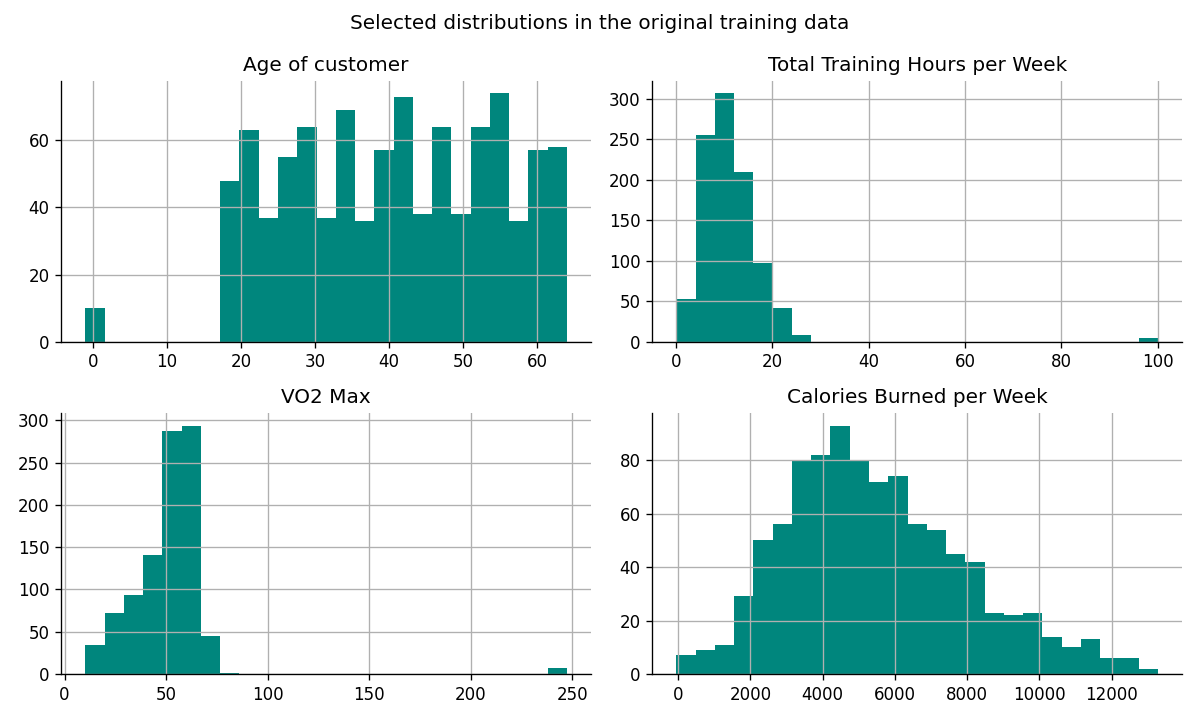

In [5]:
def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=120)
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

plot_columns = ["Age of customer", "Total Training Hours per Week",
                "VO2 Max", "Calories Burned per Week"]
raw[plot_columns].hist(bins=25, figsize=(10, 6), color="#00867D")
plt.suptitle("Selected distributions in the original training data")
plt.tight_layout()
show_figure(plt.gcf())


In [6]:
shared_ids = set(raw[ID].dropna()) & set(test[ID].dropna())
print(f"IDs shared between the two files: {len(shared_ids)}")


IDs shared between the two files: 465


The 465 shared IDs may refer to the same customers or to independently assigned identifiers.
Their meaning is unresolved, so the course test score is not conclusive evidence of independent performance.


<a id="phase-3"></a>

# 3. Data Preparation

We remove missing labels and duplicate training observations, then split training and validation by ID.
Evaluation rows and labels remain the same across all variants.


In [7]:
data = raw.dropna(subset=[TARGET]).copy()
data = data.drop_duplicates(subset=[column for column in data if column != ID])
assert data[TARGET].isin([0, 1]).all()
assert data[ID].notna().all()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_index, val_index = next(splitter.split(data, groups=data[ID]))
train = data.iloc[train_index].copy()
validation = data.iloc[val_index].copy()
y_train = train[TARGET].astype(int)
y_val = validation[TARGET].astype(int)
groups_train = train[ID]
assert set(train[ID]).isdisjoint(set(validation[ID]))
assert y_train.nunique() == y_val.nunique() == 2
print(f"Labeled rows without duplicates: {len(data)} | Training: {len(train)} | Validation: {len(validation)}")


Labeled rows without duplicates: 976 | Training: 780 | Validation: 196


**Fixed rules:** Remove IDs and represent dates as a day offset. The cleaned variant corrects
country values and treats invalid numbers as missing. We assume total hours sum the three sports;
inconsistent totals are also imputed.


In [8]:
def make_features(frame, clean=False):
    X = frame.drop(columns=[ID, TARGET], errors="ignore").copy()
    dates = pd.to_datetime(X.pop(DATE), format="%Y-%m-%d", errors="coerce")
    X["Update day offset"] = (dates - pd.Timestamp("2024-01-01")).dt.days
    if clean:
        X["Ctry"] = X["Ctry"].replace({"Germayn": "Germany", "UnknownLand": np.nan})
        numeric = X.select_dtypes(include="number").columns.drop("Update day offset")
        X[numeric] = X[numeric].mask(X[numeric] < 0)
        hours = [column for column in X if "Hours per Week" in column]
        X[hours] = X[hours].mask(X[hours] > 168)
        X.loc[inconsistent_hours(X), TOTAL_HOURS] = np.nan
    for column in X.select_dtypes(exclude="number"):
        X[column] = X[column].astype(object)
    return X

sample_features = make_features(train)
num_columns = sample_features.select_dtypes(include="number").columns.tolist()
cat_columns = sample_features.select_dtypes(exclude="number").columns.tolist()
print(f"Model inputs: {len(num_columns)} numeric, {len(cat_columns)} categorical")


Model inputs: 11 numeric, 8 categorical


Imputation, scaling and encoding are combined with the model in a pipeline.
Cross-validation therefore learns these steps only from each training fold.


In [9]:
def make_pipeline(classifier, strategy="median", scale=True, select=False):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy=strategy, keep_empty_features=True)),
        ("scale", StandardScaler() if scale else "passthrough"),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric, num_columns),
        ("categorical", categorical, cat_columns),
    ])
    selection = SelectFromModel(RandomForestClassifier(
        n_estimators=100, random_state=SEED, n_jobs=1), threshold="median") if select else "passthrough"
    return Pipeline([("prepare", preprocessing), ("select", selection), ("model", clone(classifier))])


In [10]:
def evaluate_model(model, X_train, y_train, X_val, y_val):
    train_prediction = model.predict(X_train)
    val_prediction = model.predict(X_val)
    train_f1 = f1_score(y_train, train_prediction, average="macro", zero_division=0)
    val_f1 = f1_score(y_val, val_prediction, average="macro", zero_division=0)
    return {
        "Training accuracy": accuracy_score(y_train, train_prediction),
        "Validation accuracy": accuracy_score(y_val, val_prediction),
        "Training macro-F1": train_f1, "Validation macro-F1": val_f1,
        "F1 gap": train_f1 - val_f1,
    }


**Initial logistic baseline:** We vary preparation while keeping the algorithm and validation rows fixed.
The first variant uses mean imputation without scaling.


In [11]:
logistic = LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED)
preparations = {
    "Minimal": ("mean", False, False),
    "Median": ("median", False, False),
    "Cleaned": ("median", True, False),
    "Cleaned + scaled": ("median", True, True),
}
preparation_rows = []
for name, (strategy, clean, scale) in preparations.items():
    X_train = make_features(train, clean=clean)
    X_val = make_features(validation, clean=clean)
    model = make_pipeline(logistic, strategy=strategy, scale=scale)
    model.fit(X_train, y_train)
    scores = evaluate_model(model, X_train, y_train, X_val, y_val)
    preparation_rows.append({"Variant": name, **scores})
preparation_results = pd.DataFrame(preparation_rows)
baseline_f1 = preparation_results.iloc[0]["Validation macro-F1"]
preparation_results["F1 change from baseline"] = preparation_results["Validation macro-F1"] - baseline_f1
preparation_results["Accuracy change from baseline"] = (
    preparation_results["Validation accuracy"] - preparation_results.iloc[0]["Validation accuracy"])
preparation_results["Relative F1 change (%)"] = (
    100 * preparation_results["F1 change from baseline"] / baseline_f1)
display(preparation_results.round(3))


,Variant,Training accuracy,Validation accuracy,Training macro-F1,Validation macro-F1,F1 gap,F1 change from baseline,Accuracy change from baseline,Relative F1 change (%)
0,Minimal,0.808,0.740,0.798,0.732,0.066,0.000,0.000,0.000
1,Median,0.806,0.745,0.797,0.738,0.059,0.006,0.005,0.779
2,Cleaned,0.796,0.755,0.786,0.748,0.038,0.016,0.015,2.211
3,Cleaned + scaled,0.797,0.755,0.788,0.748,0.039,0.016,0.015,2.211


Preparation for the model comparison: Cleaned


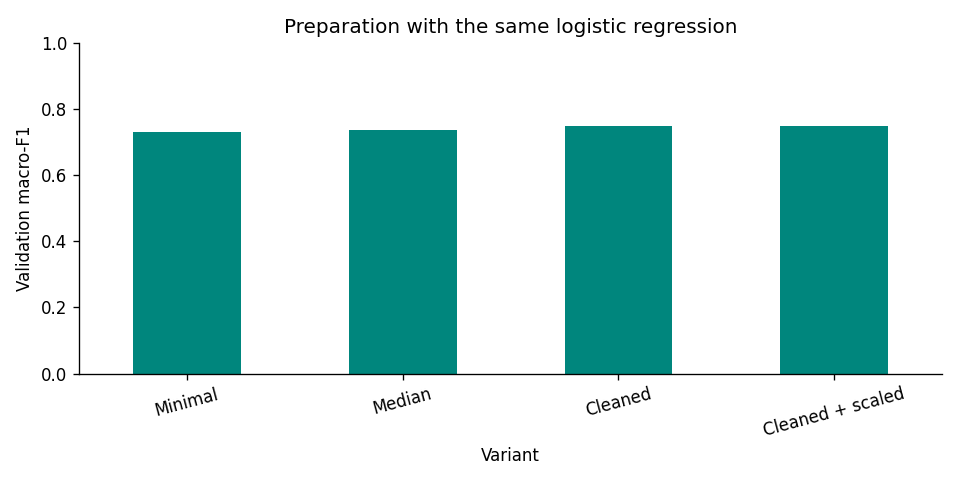

In [12]:
best_preparation = preparation_results.loc[preparation_results["Validation macro-F1"].idxmax(), "Variant"]
strategy, clean, scale = preparations[best_preparation]
X_train = make_features(train, clean=clean)
X_val = make_features(validation, clean=clean)
print("Preparation for the model comparison:", best_preparation)

axis = preparation_results.plot.bar(x="Variant", y="Validation macro-F1", legend=False,
                                    ylim=(0, 1), rot=15, color="#00867D", figsize=(8, 4))
axis.set_title("Preparation with the same logistic regression")
axis.set_ylabel("Validation macro-F1")
plt.tight_layout()
show_figure(axis.figure)


<a id="phase-4"></a>

# 4. Modeling

We compare three model families with the same preparation, then check feature selection and tune
the two strongest families using a small search space. The selection metric remains macro-F1.


In [13]:
models = {
    "Logistic regression": logistic,
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
}
model_rows = []
fitted_models = {}
for name, classifier in models.items():
    model = make_pipeline(classifier, strategy=strategy, scale=scale)
    model.fit(X_train, y_train)
    scores = evaluate_model(model, X_train, y_train, X_val, y_val)
    model_rows.append({"Model": name, "Stage": "Baseline", **scores})
    fitted_models[(name, "Baseline")] = model


**Feature selection:** A random forest retains encoded features with at least median importance.
The selector is trained within the pipeline; we also check for decreases in performance.


In [14]:
selection_rows = []
for name, classifier in models.items():
    model = make_pipeline(classifier, strategy=strategy, scale=scale, select=True)
    model.fit(X_train, y_train)
    scores = evaluate_model(model, X_train, y_train, X_val, y_val)
    model_rows.append({"Model": name, "Stage": "Feature selection", **scores})
    fitted_models[(name, "Feature selection")] = model
    selected = model.named_steps["select"].get_support()
    selection_rows.append({"Model": name, "Encoded columns": len(selected),
                           "Retained": int(selected.sum())})
display(pd.DataFrame(selection_rows))


,Model,Encoded columns,Retained
0,Logistic regression,47,24
1,Decision tree,47,24
2,Random forest,47,24


**Tuning:** Three grouped folds within the training set; model families are selected using validation.
Feature selection is relearned within each training fold of the search.


In [15]:
parameter_grids = {
    "Logistic regression": {"model__C": [0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]},
    "Decision tree": {"model__max_depth": [3, 5, None], "model__min_samples_leaf": [1, 5]},
    "Random forest": {"model__max_depth": [5, None], "model__min_samples_leaf": [1, 5]},
}
family_scores = pd.DataFrame(model_rows).groupby("Model")["Validation macro-F1"].max()
top_families = family_scores.nlargest(2).index
cv = GroupKFold(n_splits=3)
for name in top_families:
    selector = SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1), threshold="median")
    parameters = {**parameter_grids[name], "select": ["passthrough", selector]}
    pipeline = make_pipeline(models[name], strategy=strategy, scale=scale)
    search = GridSearchCV(pipeline, parameters, scoring="f1_macro", cv=cv, n_jobs=1, error_score="raise")
    search.fit(X_train, y_train, groups=groups_train)
    model = search.best_estimator_
    model_rows.append({"Model": name, "Stage": "Tuning", **evaluate_model(model, X_train, y_train, X_val, y_val)})
    fitted_models[(name, "Tuning")] = model
    print(name, {key: value for key, value in search.best_params_.items() if key != "select"})
    print("Feature selection:", search.best_params_["select"] != "passthrough")


Logistic regression {'model__C': 0.1, 'model__class_weight': None}
Feature selection: False


Random forest {'model__max_depth': None, 'model__min_samples_leaf': 1}
Feature selection: False


,Model,Stage,Training accuracy,Validation accuracy,Training macro-F1,Validation macro-F1,F1 gap
3,Logistic regression,Feature selection,0.797,0.760,0.787,0.754,0.033
6,Logistic regression,Tuning,0.805,0.760,0.794,0.752,0.042
0,Logistic regression,Baseline,0.796,0.755,0.786,0.748,0.038
2,Random forest,Baseline,1.000,0.745,1.000,0.735,0.265
7,Random forest,Tuning,1.000,0.745,1.000,0.735,0.265
5,Random forest,Feature selection,1.000,0.740,1.000,0.728,0.272
4,Decision tree,Feature selection,1.000,0.653,1.000,0.646,0.354
1,Decision tree,Baseline,1.000,0.622,1.000,0.617,0.383


Selected on the fixed split: Logistic regression | Feature selection


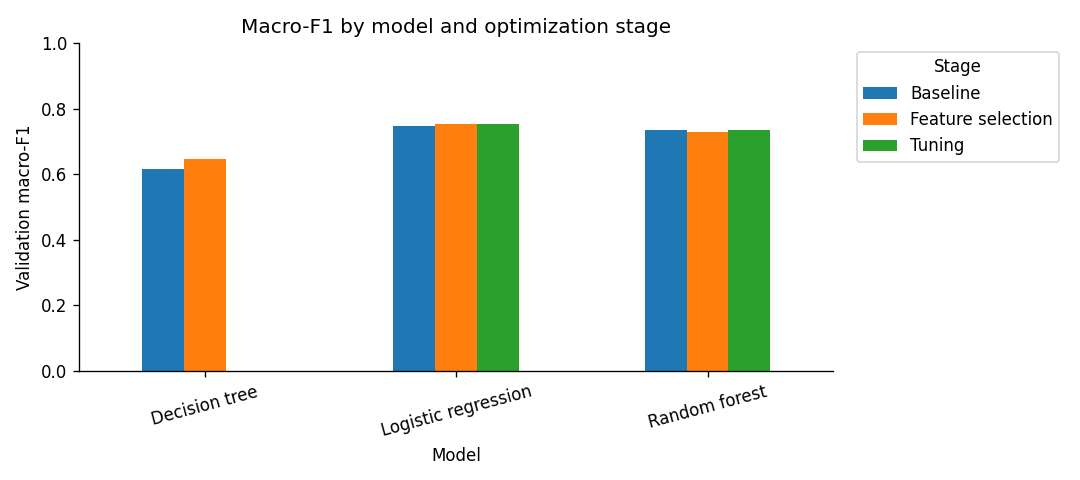

In [16]:
model_results = pd.DataFrame(model_rows)
ranking = model_results.sort_values(["Validation macro-F1", "Validation accuracy"], ascending=False, kind="stable")
display(ranking.round(3))
best = ranking.iloc[0]
best_model = fitted_models[(best["Model"], best["Stage"])]
print("Selected on the fixed split:", best["Model"], "|", best["Stage"])

comparison = model_results.pivot(index="Model", columns="Stage", values="Validation macro-F1")
axis = comparison.plot.bar(ylim=(0, 1), rot=15, figsize=(9, 4))
axis.legend(title="Stage", loc="upper left", bbox_to_anchor=(1.02, 1))
axis.set_title("Macro-F1 by model and optimization stage")
axis.set_ylabel("Validation macro-F1")
plt.tight_layout()
show_figure(axis.figure)


**Sensitivity:** Five grouped splits compare the two baseline models with preparation held fixed.
This check does not repeat the entire selection procedure or change our model choice.


In [17]:
stability_rows = []
for split_seed in [7, 21, 42, 84, 123]:
    split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=split_seed)
    a, b = next(split.split(data, groups=data[ID]))
    split_train, split_val = data.iloc[a], data.iloc[b]
    assert set(split_train[ID]).isdisjoint(set(split_val[ID]))
    for name in ["Logistic regression", "Random forest"]:
        candidate = clone(fitted_models[(name, "Baseline")])
        candidate.fit(make_features(split_train, clean=clean), split_train[TARGET].astype(int))
        prediction = candidate.predict(make_features(split_val, clean=clean))
        stability_rows.append({"Seed": split_seed, "Model": name,
                               "Macro-F1": f1_score(split_val[TARGET].astype(int), prediction, average="macro")})
stability_results = pd.DataFrame(stability_rows).pivot(index="Seed", columns="Model", values="Macro-F1")
display(stability_results.round(3))


Model,Logistic regression,Random forest
Seed,,
7,0.753,0.793
21,0.729,0.751
42,0.748,0.735
84,0.757,0.763
123,0.760,0.768


<a id="phase-5"></a>

# 5. Evaluation

With the model choice fixed, we refit this configuration on training plus validation
and evaluate it on all 500 rows of the provided course test file.


In [18]:
X_development = make_features(data, clean=clean)
y_development = data[TARGET].astype(int)
X_test = make_features(test, clean=clean)
assert test[TARGET].notna().all() and test[TARGET].isin([0, 1]).all()
y_test = test[TARGET].astype(int)

final_model = clone(best_model)
final_model.fit(X_development, y_development)
final_prediction = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, final_prediction)
test_f1 = f1_score(y_test, final_prediction, average="macro", zero_division=0)
display(pd.DataFrame({
    "Accuracy": [best["Validation accuracy"], test_accuracy],
    "Macro-F1": [best["Validation macro-F1"], test_f1],
}, index=["Validation before refitting", "Provided course test"]).round(3))


,Accuracy,Macro-F1
Validation before refitting,0.76,0.754
Provided course test,0.79,0.780


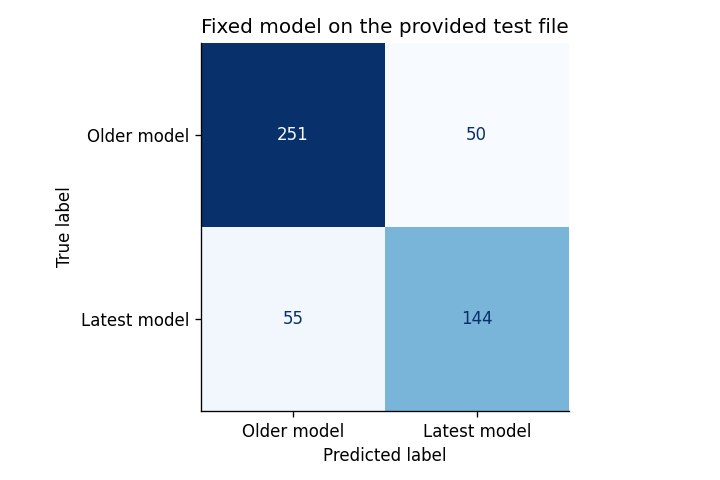

              precision    recall  f1-score   support

           0       0.82      0.83      0.83       301
           1       0.74      0.72      0.73       199

    accuracy                           0.79       500
   macro avg       0.78      0.78      0.78       500
weighted avg       0.79      0.79      0.79       500



**Error pattern:** 55 of 199 users of the latest model are classified as users of an older model (**27.6%**).

In [19]:
figure, axis = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(y_test, final_prediction, labels=[0, 1],
    display_labels=["Older model", "Latest model"], cmap="Blues", colorbar=False, ax=axis)
axis.set_title("Fixed model on the provided test file")
plt.tight_layout()
show_figure(figure)
print(classification_report(y_test, final_prediction, labels=[0, 1], zero_division=0))

missed_latest = int(((y_test == 1) & (final_prediction == 0)).sum())
actual_latest = int((y_test == 1).sum())
display(Markdown(
    f"**Error pattern:** {missed_latest} of {actual_latest} users of the latest model "
    f"are classified as users of an older model "
    f"(**{missed_latest / actual_latest:.1%}**)."
))


The model choice applies to the fixed split; the sensitivity check does not establish general superiority.
The previously evaluated course test is not a new independent test. Overlapping IDs and unclear feature
timing limit interpretation; the analysis does not predict future purchases or establish causation.


In [20]:
best_preparation_f1 = preparation_results["Validation macro-F1"].max()
display(Markdown(
    f"**Result:** {best['Model']} ({best['Stage']}). "
    f"Preparation: {best_preparation}. "
    f"Initial logistic baseline macro-F1: **{baseline_f1:.3f}**; "
    f"best preparation: **{best_preparation_f1:.3f}**. "
    f"Provided course test: Accuracy **{test_accuracy:.3f}**, Macro-F1 **{test_f1:.3f}**."
))


**Result:** Logistic regression (Feature selection). Preparation: Cleaned. Initial logistic baseline macro-F1: **0.732**; best preparation: **0.748**. Provided course test: Accuracy **0.790**, Macro-F1 **0.780**.

<a id="phase-6"></a>

# 6. Deployment

We export the complete prediction pipeline and three original example customers for the Gradio demo.
The app loads this fixed model; training and selection remain in the notebook. Details: [process overview](CRISP-DM-Process-Overview.md).


In [21]:
assert len(X_test) == len(test) == 500
assert set(train[ID]).isdisjoint(set(validation[ID]))
for path in [TRAIN_FILE, TEST_FILE]:
    assert hashlib.sha256(path.read_bytes()).hexdigest() == input_hashes[path.name]

print("Original files unchanged; all test rows retained; internal groups separated.")
display(pd.Series(input_hashes, name="SHA-256").rename_axis("File").to_frame())
display(pd.Series({package: version(package) for package in
    ["numpy", "pandas", "scikit-learn", "matplotlib", "ipykernel"]}, name="Version").to_frame())
print("Python:", platform.python_version())


Original files unchanged; all test rows retained; internal groups separated.


,SHA-256
File,
triathlon_watch_training_data_final.csv,2dc7199529804a1ef6c3e78b1ce709fa4b70ffcb0fef6c...
triathlon_watch_test_data_final.csv,a18dbf03ae85ea018f9730a74182e9c7f6f28e79b0da1e...


,Version
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
matplotlib,3.10.9
ipykernel,7.2.0


Python: 3.14.4


In [22]:
import cloudpickle
from sklearn.preprocessing import FunctionTransformer

input_columns = raw.columns.drop([ID, TARGET]).tolist()
inference_pipeline = Pipeline([
    ("features", FunctionTransformer(make_features, kw_args={"clean": clean}, validate=False)),
    ("classifier", final_model),
])
assert np.array_equal(inference_pipeline.predict(test[input_columns]), final_prediction)

bundle = {
    "pipeline": inference_pipeline,
    "columns": input_columns,
    "numeric_columns": raw[input_columns].select_dtypes(include="number").columns.tolist(),
    "categories": {column: sorted(raw[column].dropna().unique().tolist())
                   for column in input_columns if column not in numeric_columns and column != DATE},
    "examples": test[input_columns].head(3).to_dict(orient="records"),
    "example_ids": test[ID].head(3).tolist(),
    "versions": {package: version(package) for package in ["numpy", "pandas", "scikit-learn", "cloudpickle"]},
    "python": platform.python_version(),
}
with (ROOT / "model.pkl").open("wb") as model_file:
    cloudpickle.dump(bundle, model_file)
print("Exported model.pkl: complete pipeline and three original example customers.")


Exported model.pkl: complete pipeline and three original example customers.
